## 1. Setup and loading the data

In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

# Work out the project folder whether the notebook runs from /notebooks or from the project root
ROOT = Path.cwd()
if not (ROOT / "data" / "clean").exists():
    ROOT = ROOT.parent
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

# Chart styling (colours validated for colour-blind readers)
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})

STAPLES = ["Rice", "Tur/Arhar Dal", "Sugar", "Milk", "Onion"]
LABELS = {"Rice": "Rice", "Tur/Arhar Dal": "Tur dal", "Sugar": "Sugar", "Milk": "Milk", "Onion": "Onion"}

df = pd.read_csv(ROOT / "data" / "clean" / "prices_long.csv", parse_dates=["date"])
print(f"Rows in the combined table: {len(df):,}")
print(f"Commodities: {df['commodity'].nunique()}   Dates: {df['date'].nunique()}")
display(df.head())

Rows in the combined table: 3,198
Commodities: 41   Dates: 39


,date,commodity,price_type,price_raw,source_file,price_per_kg
0,2021-10-15,Atta (Wheat),retail,28.99,allindia_2026-10-15_multi-span.xls.xls,28.99
1,2022-10-15,Atta (Wheat),retail,34.00,allindia_2026-10-15_multi-span.xls.xls,34.00
2,2023-10-15,Atta (Wheat),retail,35.90,allindia_2024-10-15_m7-12.xls.xls,35.90
3,2023-11-15,Atta (Wheat),retail,36.60,allindia_2024-10-15_m7-12.xls.xls,36.60
4,2023-12-15,Atta (Wheat),retail,36.29,allindia_2024-10-15_m7-12.xls.xls,36.29


## 2. Data quality checks

Before analysing anything, I check what the data actually contains. The units differ between the two price types, so this step also documents how I made them comparable.

- **Retail** prices are in ₹ per kg (milk: ₹ per litre).
- **Wholesale** prices are published in ₹ per **quintal** (100 kg). `build_dataset.py` divides them by 100, so both are in `price_per_kg` and can be compared directly.

In [15]:
five = df[df["commodity"].isin(STAPLES)].copy()

# 1) Missing values for the five staples
print("Missing prices for the five staples:", int(five["price_per_kg"].isna().sum()))

# 2) Duplicate date/commodity/price-type rows
print("Duplicate rows:", int(five.duplicated(["date", "commodity", "price_type"]).sum()))

# 3) Which dates do I have? Monthly series from Oct 2023, plus single October snapshots before that
dates = sorted(five["date"].unique())
print("All snapshot dates:", len(dates))
print("Earlier single snapshots:", [str(pd.Timestamp(d).date()) for d in dates if pd.Timestamp(d) < pd.Timestamp("2023-10-01")])

# 4) Keep the continuous monthly window and check there are no gaps
monthly = five[five["date"] >= "2023-10-01"]
months = pd.PeriodIndex(sorted(monthly["date"].unique()), freq="M")
expected = pd.period_range(months.min(), months.max(), freq="M")
print(f"Monthly window: {months.min()} to {months.max()}, {len(months)} months, gaps: {list(expected.difference(months))}")

# 5) Sanity check on ranges
display(monthly.groupby(["commodity", "price_type"])["price_per_kg"].agg(["min", "median", "max"]).round(1))

Missing prices for the five staples: 0
Duplicate rows: 0
All snapshot dates: 39
Earlier single snapshots: ['2021-10-15', '2022-10-15']
Monthly window: 2023-10 to 2026-10, 37 months, gaps: []


min  median    max
commodity     price_type                      
Milk          retail       57.0    58.9   61.4
              wholesale    53.9    55.4   57.8
Onion         retail       24.7    33.4   59.7
              wholesale    18.7    25.9   49.9
Rice          retail       41.9    43.3   47.5
              wholesale    37.3    38.5   42.7
Sugar         retail       43.5    45.6   59.2
              wholesale    40.4    42.4   54.4
Tur/Arhar Dal retail      114.5   130.5  168.8
              wholesale   105.1   121.5  156.6

**What the checks show.** There are no missing values and no duplicates for the five staples, and the monthly window has no gaps. The older October snapshots (2021 and 2022) are not used in the monthly statistics, because they are not consecutive months.

In [16]:
# Wide tables: one row per month, one column per staple
def wide(price_type):
    sub = monthly[monthly["price_type"] == price_type]
    return sub.pivot(index="date", columns="commodity", values="price_per_kg")[STAPLES].sort_index()

retail, wholesale = wide("retail"), wide("wholesale")
mom_retail = retail.pct_change() * 100      # month-on-month % change
mom_wholesale = wholesale.pct_change() * 100
print(retail.shape, wholesale.shape)
display(retail.tail(3).round(1))

(37, 5) (37, 5)


commodity,Rice,Tur/Arhar Dal,Sugar,Milk,Onion
date,,,,,
2026-08-15,45.2,122.6,51.6,60.2,36.3
2026-09-15,46.4,124.4,59.2,61.3,53.9
2026-10-15,47.5,130.5,57.4,61.4,52.7


## 3. How did prices move? (Question 1)

Each panel shows one staple, with retail and wholesale on the same axis (₹/kg; milk ₹/litre). Every panel spans the **same range relative to that staple's typical price** (45% to 185% of its three-year median retail price), so a line that looks flat really is stable, and wiggles can be compared across panels.

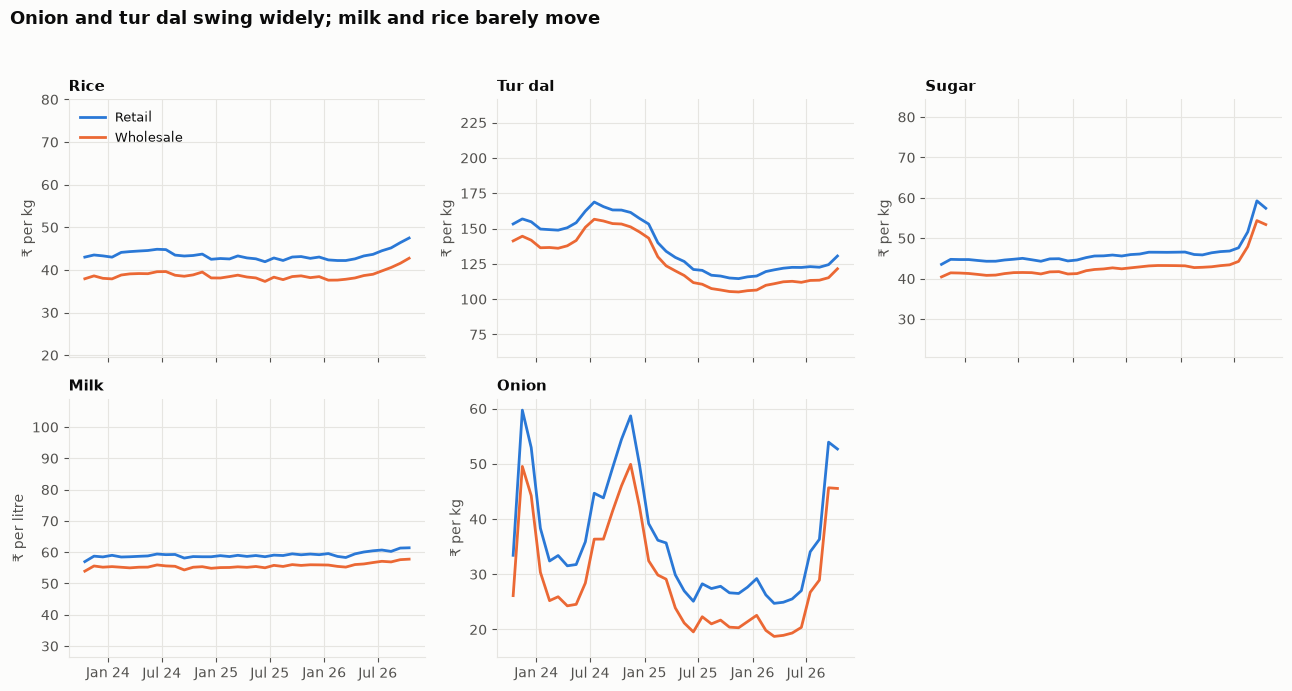

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, name in zip(axes.flat, STAPLES):
    ax.plot(retail.index, retail[name], color=BLUE, lw=2, label="Retail")
    ax.plot(wholesale.index, wholesale[name], color=ORANGE, lw=2, label="Wholesale")
    med = retail[name].median()
    ax.set_ylim(0.45 * med, 1.85 * med)     # same proportional window for every staple
    ax.set_title(LABELS[name], loc="left", fontsize=11, fontweight="bold")
    ax.set_ylabel("₹ per litre" if name == "Milk" else "₹ per kg")
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes.flat[0].legend(frameon=False, loc="upper left", fontsize=9)
axes.flat[-1].axis("off")
fig.suptitle("Onion and tur dal swing widely; milk and rice barely move", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(IMAGES / "01_price_trends.png", dpi=150)
plt.show()

## 4. Which staples are the most volatile? (Question 2)

I use the **standard deviation of month-on-month % change**: how much the price typically jumps from one month to the next. It is a better volatility measure than the spread of price levels, because a steady trend does not count as volatility.

In [18]:
vol = pd.DataFrame({
    "avg_price": retail.mean(),
    "min_price": retail.min(),
    "max_price": retail.max(),
    "max_vs_min": retail.max() / retail.min(),
    "volatility_pct": mom_retail.std(),          # std dev of monthly % change
    "biggest_monthly_rise_pct": mom_retail.max(),
    "biggest_monthly_fall_pct": mom_retail.min(),
}).round(2).sort_values("volatility_pct", ascending=False)
vol.index = [LABELS[i] for i in vol.index]
display(vol)

,avg_price,min_price,max_price,max_vs_min,volatility_pct,biggest_monthly_rise_pct,biggest_monthly_fall_pct
Onion,36.27,24.73,59.72,2.41,19.14,78.64,-27.60
Sugar,46.31,43.54,59.25,1.36,2.93,14.89,-3.09
Tur dal,137.45,114.52,168.75,1.47,2.73,5.31,-8.64
Rice,43.48,41.92,47.48,1.13,1.39,2.72,-2.88
Milk,59.12,56.98,61.40,1.08,0.95,3.07,-1.94


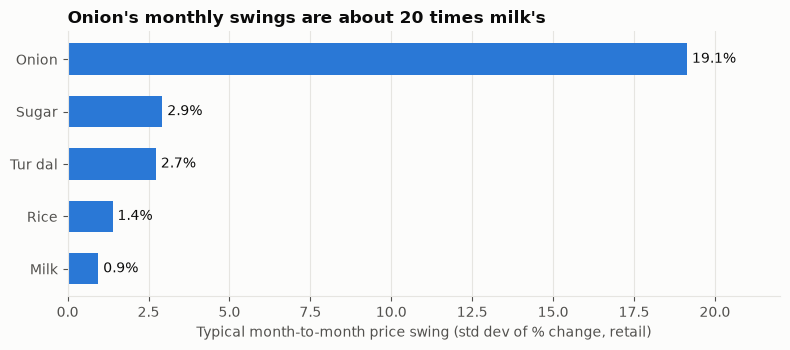

In [19]:
order = vol["volatility_pct"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(order.index, order.values, color=BLUE, height=0.6)
for b, v in zip(bars, order.values):
    ax.text(v + 0.15, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", color=INK, fontsize=10)
ax.set_xlabel("Typical month-to-month price swing (std dev of % change, retail)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_xlim(0, order.max() * 1.15)
ax.set_title("Onion's monthly swings are about 20 times milk's", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(IMAGES / "02_volatility.png", dpi=150)
plt.show()

## 5. How big is the retail–wholesale gap? (Question 3)

The **gap** is the retail price minus the wholesale price. As a share of the wholesale price, it shows how much a retailer earns before its own costs. I measure it in ₹ per kg and in % of the wholesale price.

In [20]:
gap_abs = retail - wholesale
gap_pct = gap_abs / wholesale * 100

gap = pd.DataFrame({
    "avg_gap_rs": gap_abs.mean(),
    "avg_gap_pct_of_wholesale": gap_pct.mean(),
    "min_gap_pct": gap_pct.min(),
    "max_gap_pct": gap_pct.max(),
}).round(2).sort_values("avg_gap_pct_of_wholesale", ascending=False)
gap.index = [LABELS[i] for i in gap.index]
display(gap)

,avg_gap_rs,avg_gap_pct_of_wholesale,min_gap_pct,max_gap_pct
Onion,7.06,25.70,15.68,32.63
Rice,4.73,12.22,10.67,13.92
Tur dal,10.49,8.34,6.29,9.71
Sugar,3.38,7.86,7.15,8.98
Milk,3.48,6.26,5.55,7.00


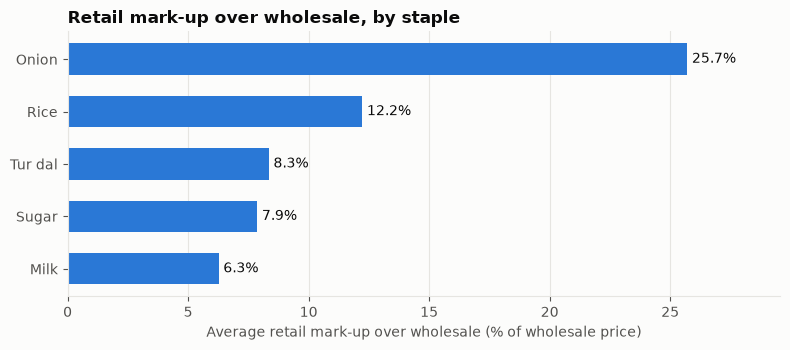

In [21]:
order = gap["avg_gap_pct_of_wholesale"].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(order.index, order.values, color=BLUE, height=0.6)
for b, v in zip(bars, order.values):
    ax.text(v + 0.2, b.get_y() + b.get_height() / 2, f"{v:.1f}%", va="center", color=INK, fontsize=10)
ax.set_xlabel("Average retail mark-up over wholesale (% of wholesale price)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_xlim(0, order.max() * 1.15)
ax.set_title("Retail mark-up over wholesale, by staple", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(IMAGES / "03_retail_wholesale_gap.png", dpi=150)
plt.show()

In [22]:
# Does the gap behave differently when wholesale prices spike (rise more than 5% in a month)?
spike = mom_wholesale > 5
rows = []
for name in STAPLES:
    rows.append({
        "staple": LABELS[name],
        "spike_months": int(spike[name].sum()),
        "avg_gap_pct_in_spike_months": gap_pct.loc[spike[name], name].mean(),
        "avg_gap_pct_other_months": gap_pct.loc[~spike[name], name].mean(),
    })
display(pd.DataFrame(rows).round(2).set_index("staple"))

,spike_months,avg_gap_pct_in_spike_months,avg_gap_pct_other_months
staple,,,
Rice,0,NaN,12.22
Tur dal,2,7.52,8.39
Sugar,2,8.28,7.84
Milk,0,NaN,6.26
Onion,13,24.12,26.56


## 6. Is there a seasonal pattern? (Question 4)

For each calendar month I average the month-on-month % change in the retail price. A red cell means prices tend to **rise** in that month, blue means they tend to **fall**. Each cell averages only **three** observations (one per year), so treat the pattern as a hint to check against more years.

Observations behind each cell: 3


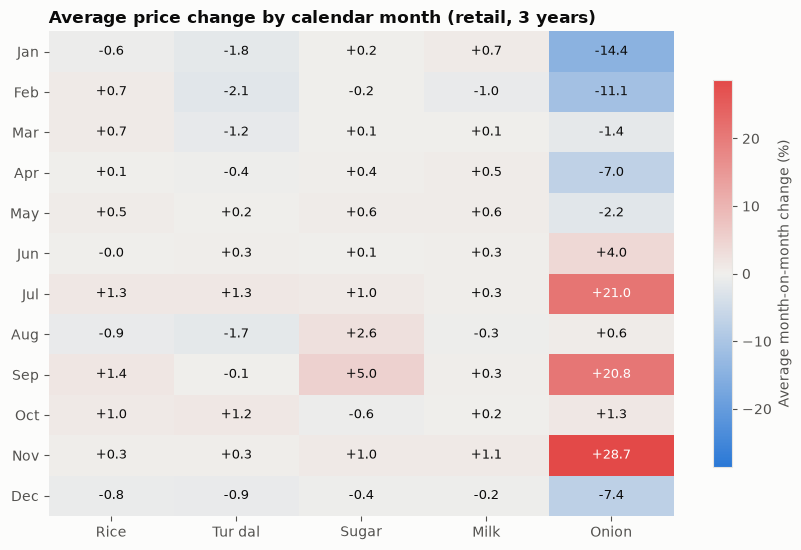

,Rice,Tur dal,Sugar,Milk,Onion
Jan,-0.6,-1.8,0.2,0.7,-14.4
Feb,0.7,-2.1,-0.2,-1.0,-11.1
Mar,0.7,-1.2,0.1,0.1,-1.4
Apr,0.1,-0.4,0.4,0.5,-7.0
May,0.5,0.2,0.6,0.6,-2.2
Jun,-0.0,0.3,0.1,0.3,4.0
Jul,1.3,1.3,1.0,0.3,21.0
Aug,-0.9,-1.7,2.6,-0.3,0.6
Sep,1.4,-0.1,5.0,0.3,20.8
Oct,1.0,1.2,-0.6,0.2,1.3


In [23]:
season = mom_retail.groupby(mom_retail.index.month).mean()
season.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season.columns = [LABELS[c] for c in season.columns]
n_obs = mom_retail.groupby(mom_retail.index.month).count().min().min()
print("Observations behind each cell:", n_obs)

cmap = LinearSegmentedColormap.from_list("blue_neutral_red", [BLUE, "#f0efec", RED])
lim = float(np.abs(season.values).max())
fig, ax = plt.subplots(figsize=(8.5, 5.6))
im = ax.imshow(season.values, cmap=cmap, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(season.shape[1]), season.columns)
ax.set_yticks(range(season.shape[0]), season.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(season.shape[0]):
    for j in range(season.shape[1]):
        v = season.values[i, j]
        ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > lim * 0.6 else INK)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Average month-on-month change (%)")
ax.set_title("Average price change by calendar month (retail, 3 years)", loc="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(IMAGES / "04_seasonality.png", dpi=150)
plt.show()
display(season.round(1))

In [24]:
# How consistent is each cell? Count the years (out of 3) in which prices ROSE in that calendar month.
years_up = (mom_retail > 0).groupby(mom_retail.index.month).sum()
years_up.index = season.index
years_up.columns = season.columns
print("Years (out of 3) in which the price rose in that month:")
display(years_up)

Years (out of 3) in which the price rose in that month:


,Rice,Tur dal,Sugar,Milk,Onion
Jan,1,1,2,3,1
Feb,1,1,1,0,0
Mar,2,1,1,2,1
Apr,2,2,3,2,1
May,2,2,3,3,2
Jun,2,1,2,2,2
Jul,2,2,3,2,3
Aug,1,0,2,1,1
Sep,2,1,2,2,3
Oct,3,1,1,2,1


**Reading the heatmap carefully.** Each cell averages only three values, so one extreme month can dominate it. The darkest cell, onion in November (+28.7%), is mostly a single event: a jump of about 79% in November 2023, followed by +7.9% in 2024 and about 0% in 2025. The table above counts in how many of the three years the price actually *rose* in each month, which is a better test of whether a pattern repeats.

## 7. Does retail follow wholesale with a delay? (Question 5)

If retail prices lag wholesale prices, a rise in wholesale gives the retailer an early warning. I correlate the wholesale month-on-month change with the retail change in the **same** month, **one month later** and **two months later**.

In [25]:
lag_rows = []
for name in STAPLES:
    row = {"staple": LABELS[name]}
    for k in (0, 1, 2):
        row[f"lag_{k}_months"] = mom_wholesale[name].corr(mom_retail[name].shift(-k))
    lag_rows.append(row)
lags = pd.DataFrame(lag_rows).set_index("staple").round(2)
display(lags)

,lag_0_months,lag_1_months,lag_2_months
staple,,,
Rice,0.95,0.02,0.16
Tur dal,0.99,0.63,0.39
Sugar,0.99,0.29,-0.05
Milk,0.90,-0.30,0.32
Onion,1.00,0.13,-0.06


## 8. Where are prices now?

Before recommending anything, I compare the latest price (15 Oct 2026) with the typical (median) price of the last three years. A price far above its usual level is a poor moment to stock up.

In [26]:
now = pd.DataFrame({
    "latest_retail": retail.iloc[-1],
    "median_3yr": retail.median(),
})
now["vs_median_pct"] = (now["latest_retail"] / now["median_3yr"] - 1) * 100
now["latest_wholesale_change_1m_pct"] = mom_wholesale.iloc[-1]
now.index = [LABELS[i] for i in now.index]
display(now.round(1).sort_values("vs_median_pct", ascending=False))

# Sugar: how big was the recent run-up?
print("Sugar retail, Jun 2026 -> Sep 2026: %+.1f%%" % ((retail.loc["2026-09-15", "Sugar"] / retail.loc["2026-06-15", "Sugar"] - 1) * 100))

,latest_retail,median_3yr,vs_median_pct,latest_wholesale_change_1m_pct
Onion,52.7,33.4,57.8,-0.3
Sugar,57.4,45.6,25.9,-1.8
Rice,47.5,43.3,9.8,2.9
Milk,61.4,58.9,4.2,0.3
Tur dal,130.5,130.5,0.0,5.5


Sugar retail, Jun 2026 -> Sep 2026: +26.5%


## 9. Findings and recommendations

### What I found
1. **Some staples are much riskier than others.** Onion's price changes by about 19.1% from one month to the next. For sugar it is 2.9%, tur dal 2.7%, rice 1.4% and milk only 0.9%. Over three years, onion's retail price went from ₹24.7 to ₹59.7 per kg, which is about 2.4 times. Milk stayed between ₹57.0 and ₹61.4 per litre.
2. **The gap between retail and wholesale is biggest for onion.** On average, retail is 25.7% above wholesale for onion (₹7.06/kg). For rice it is 12.2% (₹4.73/kg), tur dal 8.3% (₹10.49/kg, the biggest gap in rupees), sugar 7.9% (₹3.38/kg) and milk 6.3% (₹3.48/litre). This is only the gap between the two published prices. It is not the retailer's profit, because it does not include the retailer's own costs.
3. **Onion follows a seasonal pattern, and the other staples mostly do not.** Onion prices went up in July and September in all three years (about +21% a month on average) and came down in February in all three years (about −11%). The other staples move less than 1.5% a month in most months. Sugar's +5.0% in September comes mainly from one big rise in 2026, so it is not a repeating pattern. I only have three years of data, so I treat every seasonal finding as something to test with more data.
4. **Retail and wholesale prices move together in the same month** (correlation 0.90 to 1.00 for all five). One month later, only tur dal shows a clear echo (0.63), so when its wholesale price rises, retail tends to rise again the next month. For the other staples I see no useful delay. Delays shorter than a month would not show up in monthly data.
5. **Some staples are expensive right now.** On 15 October 2026, onion's retail price was 57.8% above its 3-year median. Sugar was 25.9% above, rice 9.8% above and milk 4.2% above. Tur dal was at its median. Sugar rose 26.5% between June and September 2026.

### What I would recommend to a retail chain

- **Onion: treat it as a risk, not a routine item.** Don't stock up heavily when the price is far above normal, like now. Plan purchases and promotions for February to April, when prices have tended to fall, and expect rises from July.
- **Tur dal: watch the wholesale price as an early warning.** Wholesale rose 5.5% in the last month, and past data suggests retail follows about a month later, so shelf prices may rise further. Its gap in rupees is the biggest, so deep promotions on tur dal are expensive.
- **Sugar: treat the 2026 rise as a shock, not a season.** At 25.9% above its median, this is a poor time to stock up. I would watch whether the small fall in wholesale (−1.8% last month) continues.
- **Rice and milk: buy on a regular schedule.** Their prices barely move, so timing the purchase gains very little. Milk has the thinnest gap (6.3%), so avoid deep discounts on it.

### Limits and next steps

- The data is all-India averages, so differences between states are not visible.
- It has one price per month (the 15th), so spikes between those dates can be missed.
- Three years is a short history for seasonality.
- Next, I would add more years of data and a state-level view.